In [1]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import emcee
import corner
from IPython.display import display, Math
from numba import njit
from dynesty import NestedSampler

In [2]:
from values.metrics import metrics
from values.binary_data import name_binary
from analysis.qpo_analysis import calc_freq
from analysis.qpo_analysis import f_U_err_direct
from analysis.qpo_analysis import f_L_err_direct
from models.LCC_no_bias_prior import get_L_BH
from models.LCC_no_bias_prior import get_all_L_BH
from models.LCC_no_bias_prior import get_L_best
from models.LCC_no_bias_prior import get_radii
from models.LCC_no_bias_prior import log_posterior_probability
from models.LCC_no_bias_prior import prepare_mcmc_samples
from models.LCC_no_bias_prior import ptform
from models.LCC_no_bias_prior import log_likelihood_dynesty
from models.LCC_no_bias_prior import ISCOs_dynesty

In [3]:
f_U_func,f_U_err_func,f_L_func,f_L_err_func,V_2diff,f,f_diff = calc_freq(metrics["h_LCC"])

In [4]:
L_BH = get_L_BH(f)
L_max = 5*min(L_BH)
L_best = get_L_best(f_U_func,f_L_func,V_2diff,f,f_diff,L_max)
r_best,ISCOs = get_radii(f_U_func,f_L_func,V_2diff,f,f_diff,L_max)

display(Math(rf"L_{{\mathrm{{max}}}} = {L_max:.3f} \mathrm{{m}}"))
display(Math(rf"L_{{\mathrm{{best}}}} = {L_best:.3f} \mathrm{{m}}"))
for i in range(len(r_best)):
    display(Math(rf"r_{{best,{i}}} = {r_best[i]:.3f}\mathrm{{m}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [5]:
chi_summary=np.round(np.array([L_best]+r_best)/1000,2)

In [6]:
labels = ["\ell", "r_0", "r_1", "r_2", "r_3", "r_4"]

In [7]:
n_walkers = 32
n_dim = len([L_best]+r_best)
n_steps = 10000
pos = [L_best]+r_best - (np.random.randn(n_walkers, n_dim))

f_U_err_direct_numba = njit(f_U_err_direct, cache=False, fastmath=False)
f_L_err_direct_numba = njit(f_L_err_direct, cache=False, fastmath=False)

#nwalkers, ndim = pos.shape
sampler = emcee.EnsembleSampler(
    n_walkers, n_dim, log_posterior_probability, args=(f_U_func, f_U_err_direct_numba, f_L_func, f_L_err_direct_numba, V_2diff, L_max, ISCOs, L_BH) 
)
sampler.run_mcmc(pos, n_steps, progress=True)

100%|██████████| 10000/10000 [00:12<00:00, 809.54it/s]


State([[  9863.28059418  43118.62044591  79663.24921669  96624.42095336
   75963.32835287 116299.99297679]
 [  9038.75619898  42710.95146342  76513.61603808 103977.63783385
   77520.87792448 110558.84660186]
 [  9121.72372055  43699.14819091  78267.75680569  95064.86066365
   76523.13451036 118468.68029748]
 [ 10962.81973726  42133.71815148  76511.98712676  96924.30671159
   75130.91998993 110908.09332252]
 [  9471.98013891  43820.99236014  78016.25946324  96114.81680558
   76461.16335073 120918.09235579]
 [ 10224.85603764  42805.12085622  79818.31383567  94377.07076205
   75515.25678418 106534.45314873]
 [ 10886.06285823  43342.46054281  80250.86554161  98088.03217601
   74742.23457195 118537.57318935]
 [  9318.04447285  43359.43574869  78737.79499485  96371.30431102
   76265.75872651 113139.06938889]
 [  8933.69330961  43612.36161718  80573.41598008  99764.08820748
   77539.72582095 116365.04950966]
 [ 10299.41449616  44061.37302007  79045.96770878  97467.05100224
   76293.49383088 1

(10000, 32, 6)


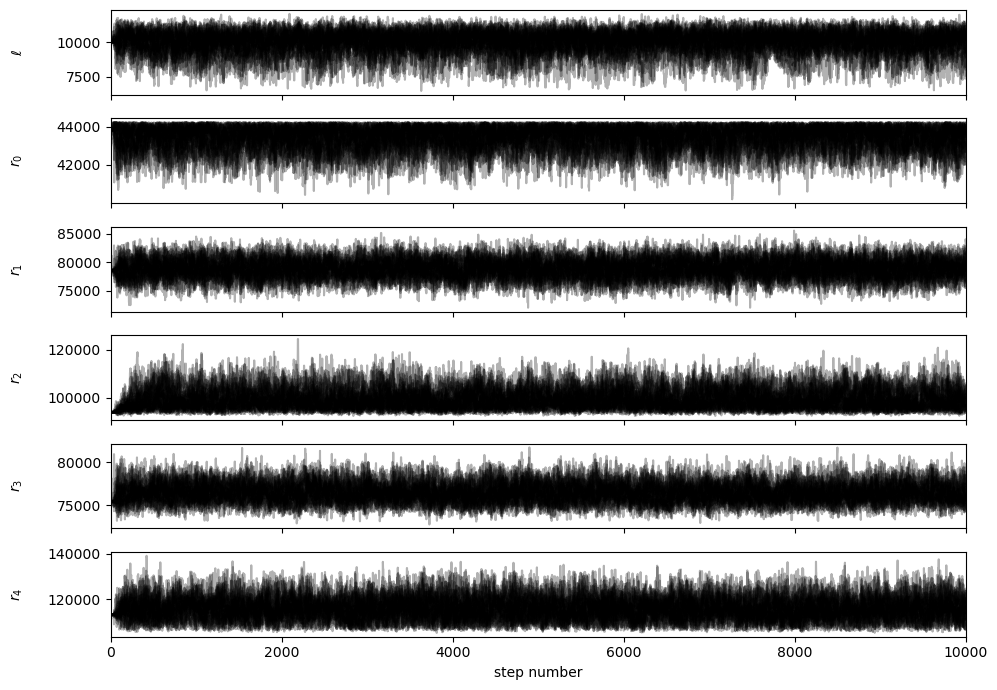

In [8]:
fig, axes = plt.subplots(n_dim, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
print(samples.shape)
for i in range(n_dim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))

    ax.set_ylabel(fr"${labels[i]}$")
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")
plt.tight_layout()

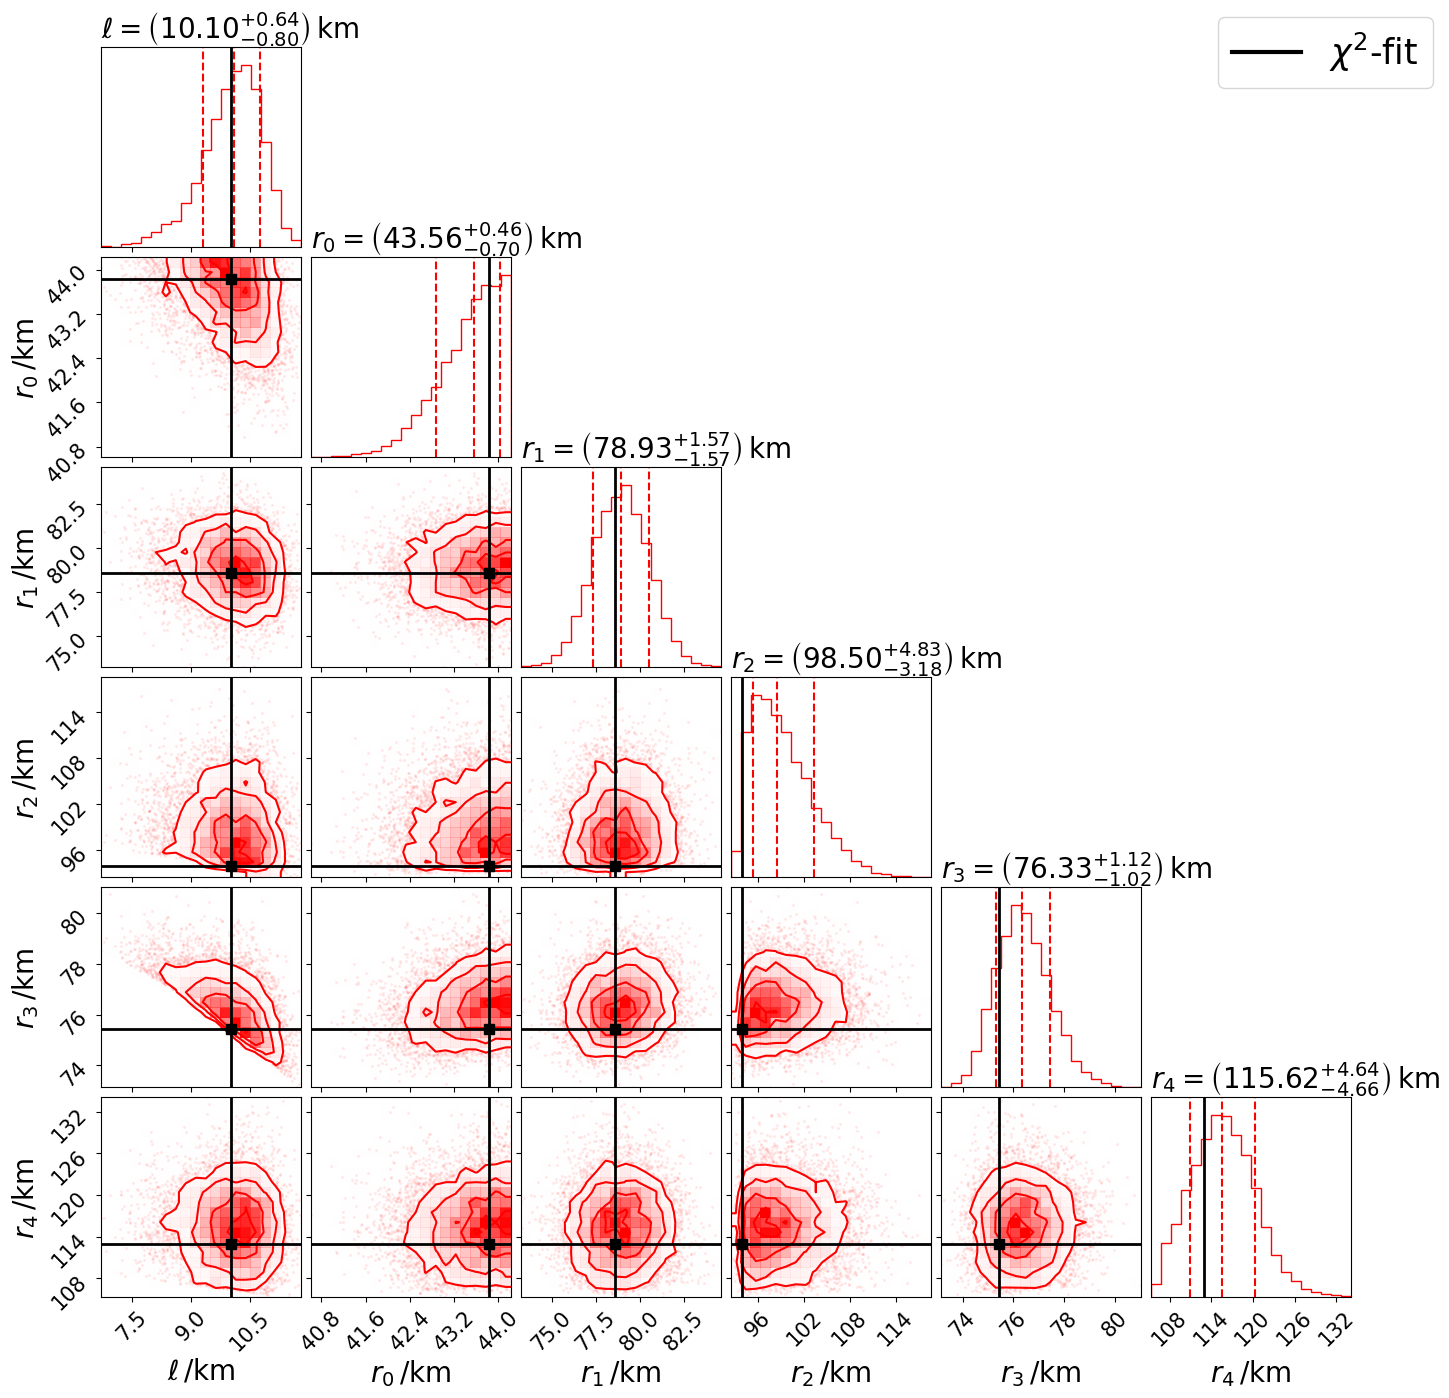

In [9]:
plt.rcParams.update({'font.size': 25,'xtick.labelsize': 15,'ytick.labelsize': 15})
flat_samples = prepare_mcmc_samples(sampler)
fig = corner.corner(
    flat_samples/1000, labels=[fr"${label}\,/\mathrm{{km}}$" for label in labels], quantiles=[0.16, 0.5, 0.84],show_titles=False,label_kwargs={"fontsize": 20},color="red"
)

mcmc_quantiles = np.array([corner.quantile(flat_samples[:, i],(0.16, 0.5, 0.84))for i in range(flat_samples.shape[1])])
mcmc_summary = np.column_stack((np.round(mcmc_quantiles[:, 1]/1000,2),np.round((mcmc_quantiles[:, 0] - mcmc_quantiles[:, 1])/1000,2),np.round((mcmc_quantiles[:, 2] - mcmc_quantiles[:, 1])/1000,2)))

axes = np.asarray(fig.axes).reshape(n_dim, n_dim)

for i, label in enumerate(labels):
    mcmc_title = (
        rf"${label} = "
        rf"\left({mcmc_summary[:,0][i]:.2f}"
        rf"^{{+{mcmc_summary[:,2][i]:.2f}}}_{{{mcmc_summary[:,1][i]:.2f}}}"
        rf"\right)\,\mathrm{{km}}$"
    )
    axes[i, i].set_title(mcmc_title,fontsize=20,loc="left",)
truths=np.array([L_best]+r_best)/1000
corner.overplot_lines(fig,truths,color="black",linewidth=2)
legend_line = Line2D([0], [0], color="black", linewidth=3, label=r"$\chi^2$-fit")
corner.overplot_points(fig, truths.reshape(1, -1),marker="s",markersize=7,markerfacecolor="black",markeredgecolor="black")
fig.legend(handles=[legend_line])
plt.savefig("../results/h_LCC_mcmc_big_prior.png",bbox_inches="tight",pad_inches=0.3,dpi=300)

In [10]:
values = []
for i in range(n_dim):
    mcmc = np.percentile(flat_samples[:, i], [16, 50, 84])
    q = np.diff(mcmc)
    txt = "{3} = {0:.3f}_{{-{1:.3f}}}^{{{2:.3f}}}"
    txt = txt.format(mcmc[1], q[0], q[1], labels[i])
    display(Math(txt))
    values.append(mcmc[1])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [11]:
ndim = len([L_best]+r_best)
f_U_err_direct_numba = njit(f_U_err_direct, cache=False, fastmath=False)
f_L_err_direct_numba = njit(f_L_err_direct, cache=False, fastmath=False)
ISCOs_dyn = ISCOs_dynesty(V_2diff,f,f_diff)

dyn_sampler = NestedSampler(log_likelihood_dynesty, ptform, ndim, logl_args=(f_U_func, f_U_err_direct_numba, f_L_func, f_L_err_direct_numba), ptform_args=(V_2diff, L_max, ISCOs_dyn, L_BH),nlive = 1000, sample="rslice")

dyn_sampler.run_nested()

100%|█████████▉| 21049/21050 [00:47<00:00, 447.61it/s, +1000 | bound: 99 | nc: 1 | ncall: 921478 | eff(%):  2.395 | loglstar: -45.972 | logz: -67.298 | dlogz:  0.001 >  1.009]


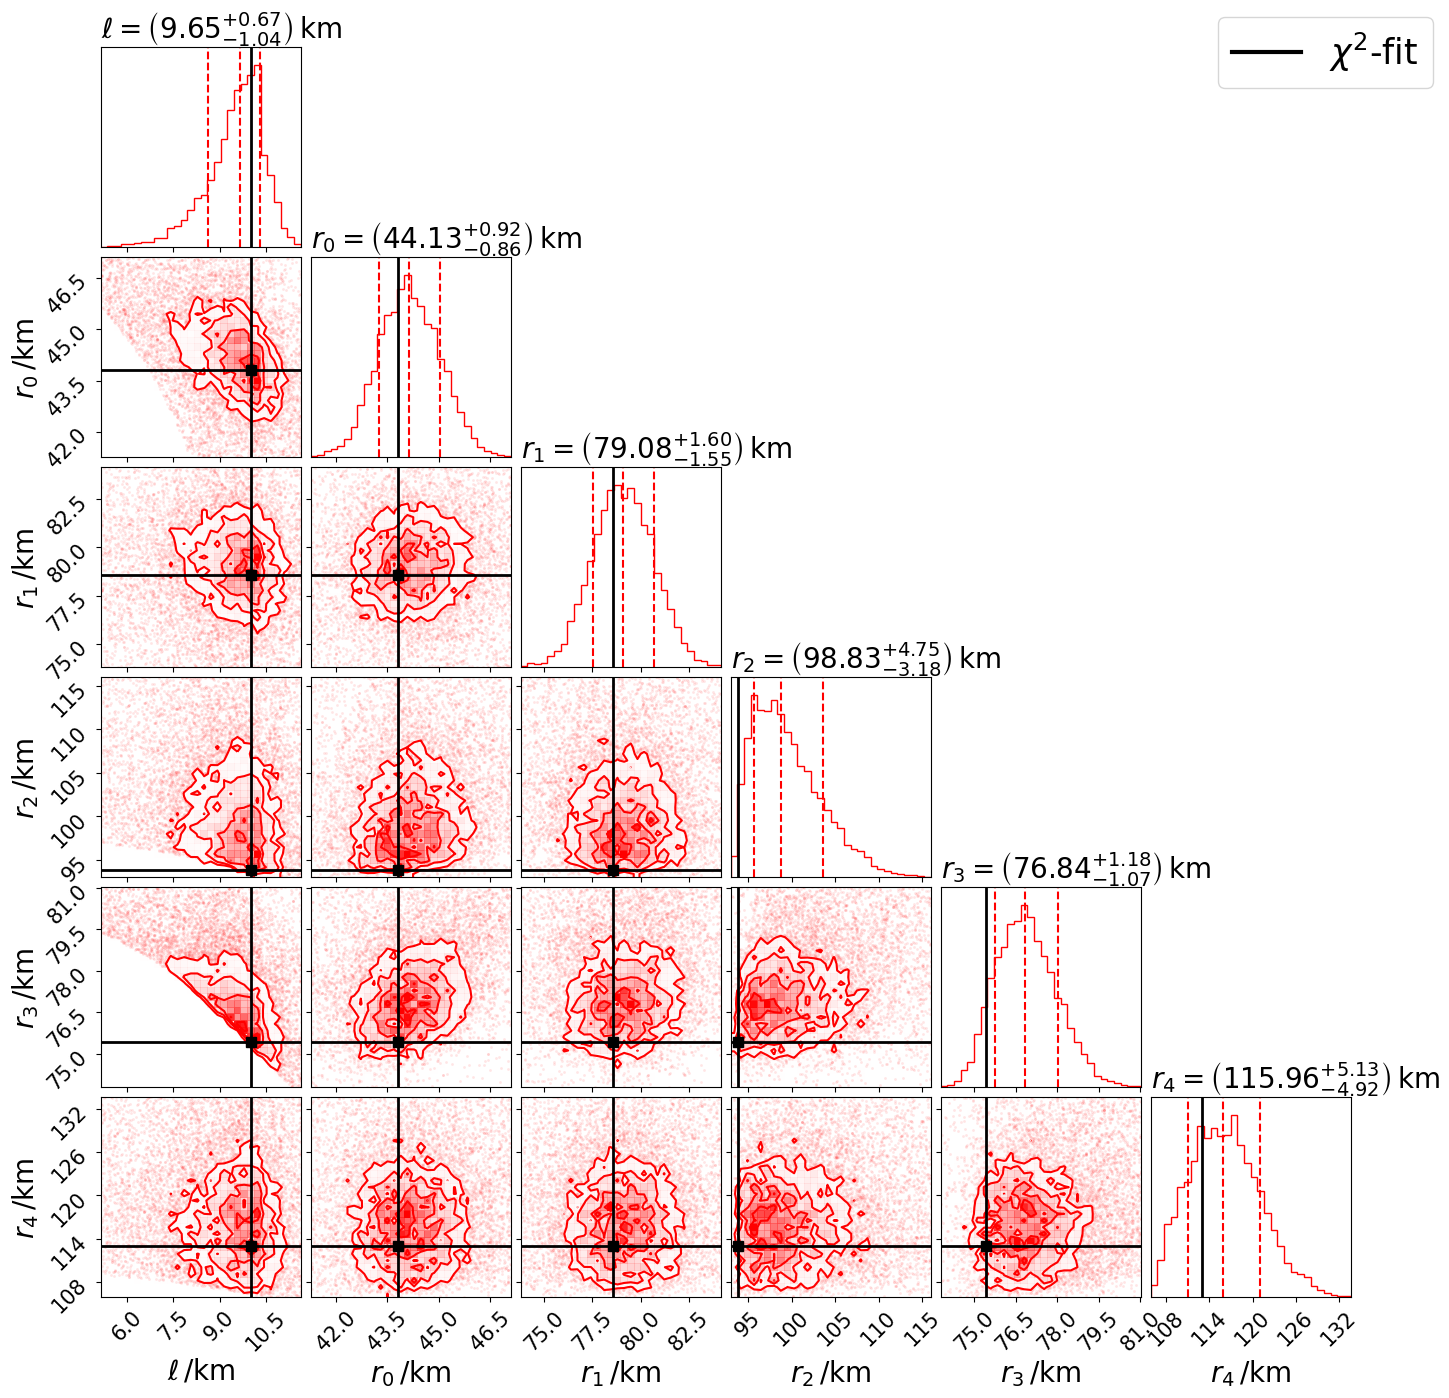

In [12]:
plt.rcParams.update({'font.size': 25,'xtick.labelsize': 15,'ytick.labelsize': 15})
dyn_results = dyn_sampler.results
dyn_samples = dyn_results.samples.copy()
dyn_weights = dyn_results.importance_weights()

fig = corner.corner(
    dyn_samples/1000, weights=dyn_weights, labels=[fr"${label}\,/\mathrm{{km}}$" for label in labels], bins=30, quantiles=[0.16, 0.5, 0.84],show_titles=False,label_kwargs={"fontsize": 20},color="red",range=[0.999] * dyn_samples.shape[1]
)

dyn_quantiles = np.array([corner.quantile(dyn_samples[:, i],(0.16, 0.5, 0.84), weights=dyn_weights)for i in range(dyn_samples.shape[1])])
dyn_summary = np.column_stack((np.round(dyn_quantiles[:, 1]/1000,2),np.round((dyn_quantiles[:, 0] - dyn_quantiles[:, 1])/1000,2),np.round((dyn_quantiles[:, 2] - dyn_quantiles[:, 1])/1000,2)))

axes = np.asarray(fig.axes).reshape(ndim, ndim)

for i, label in enumerate(labels):
    dyn_title = (
        rf"${label} = "
        rf"\left({dyn_summary[:,0][i]:.2f}"
        rf"^{{+{dyn_summary[:,2][i]:.2f}}}_{{{dyn_summary[:,1][i]:.2f}}}"
        rf"\right)\,\mathrm{{km}}$"
    )
    axes[i, i].set_title(dyn_title,fontsize=20,loc="left",)
truths=np.array([L_best]+r_best)/1000
corner.overplot_lines(fig,truths,color="black",linewidth=2)
corner.overplot_points(fig, truths.reshape(1, -1),marker="s",markersize=7,markerfacecolor="black",markeredgecolor="black")
legend_line = Line2D([0], [0], color="black", linewidth=3, label=r"$\chi^2$-fit")
fig.legend(handles=[legend_line])

plt.savefig("../results/h_LCC_dynesty_big_prior.png",bbox_inches="tight",pad_inches=0.3,dpi=300)

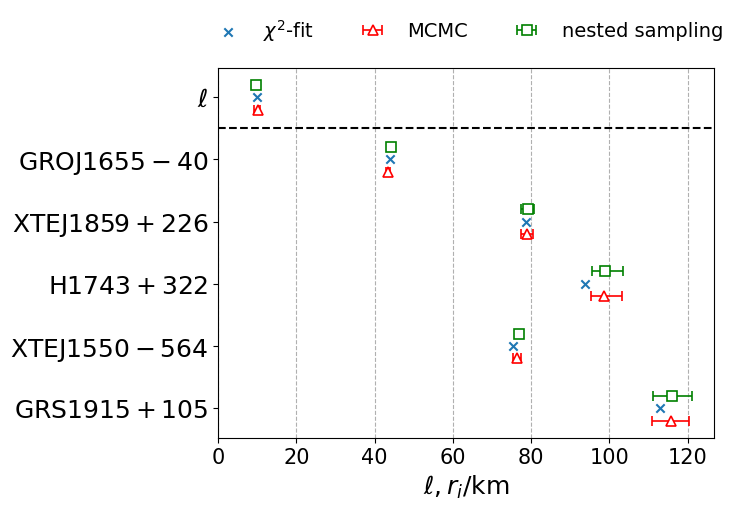

In [13]:
plt.rcParams.update({'font.size': 18,'xtick.labelsize': 15,'ytick.labelsize': 18})
y = np.array(range(len(chi_summary)))
plt.scatter(chi_summary, y,marker="x", label="$\chi^2$-fit")
plt.errorbar(mcmc_summary[:, 0], y+0.2,xerr=np.abs(mcmc_summary[:, 1:3]).T,fmt="^",markersize=7,color="red",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="MCMC",zorder=3)
plt.errorbar(dyn_summary[:, 0], y-0.2,xerr=np.abs(dyn_summary[:, 1:3]).T,fmt="s",markersize=7,color="green",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="nested sampling",zorder=3)
plt.axhline(y=0.5, color="black", linestyle="--", linewidth=1.5)

new_labels = [labels[0]] + [rf"{{\mathrm{{{name.strip()}}}}}"for name in name_binary]

plt.yticks(y,[fr"${label}$" for label in new_labels])
plt.xlabel("$\ell,r_i$/km")
plt.legend(loc="lower center",bbox_to_anchor=(0.5, 1.02),ncol=3,fontsize=14,frameon=False)
plt.grid(axis="x",linestyle="dashed")
plt.gca().invert_yaxis()
plt.xlim(left=0)

plt.savefig("../results/h_LCC_values_big_prior.png",bbox_inches="tight",pad_inches=0.3,dpi=300)
plt.show()

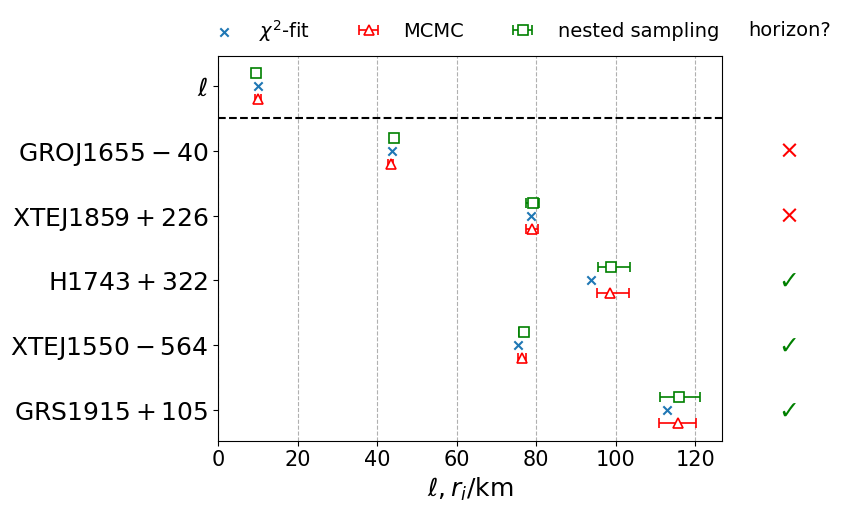

In [14]:
plt.rcParams.update({'font.size': 18,'xtick.labelsize': 15,'ytick.labelsize': 18})
y = np.array(range(len(chi_summary)))
fig = plt.figure(figsize=(8, 5))
gs = fig.add_gridspec(1, 2,width_ratios=[5, 1],wspace=0.05)

ax = fig.add_subplot(gs[0, 0])
ax_table = fig.add_subplot(gs[0, 1], sharey=ax)
ax.scatter(chi_summary, y,marker="x", label="$\chi^2$-fit")
ax.errorbar(mcmc_summary[:, 0], y+0.2,xerr=np.abs(mcmc_summary[:, 1:3]).T,fmt="^",markersize=7,color="red",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="MCMC",zorder=3)
ax.errorbar(dyn_summary[:, 0], y-0.2,xerr=np.abs(dyn_summary[:, 1:3]).T,fmt="s",markersize=7,color="green",markerfacecolor="white",markeredgewidth=1.2,elinewidth=1.2,capsize=3.5,capthick=1.2,linestyle="none",label="nested sampling",zorder=3)
ax.axhline(y=0.5, color="black", linestyle="--", linewidth=1.5)

new_labels = [labels[0]] + [rf"{{\mathrm{{{name.strip()}}}}}"for name in name_binary]

ax.set_yticks(y,[fr"${label}$" for label in new_labels])
ax.set_xlabel("$\ell,r_i$/km")

ax.grid(axis="x",linestyle="dashed")
ax.set_xlim(left=0)
ax.invert_yaxis()

ax_table.set_xticks([])

# shared y axis with main plot
ax_table.set_yticks(y)
ax_table.tick_params(axis="y", left=False, labelleft=False)

all_L_BH=get_all_L_BH(f)

for i in y[1:]:
    symbol = r"$\checkmark$" if mcmc_summary[0,0]<all_L_BH[i-1]*10**(-3) else r"$\times$"
    color = "green" if mcmc_summary[0,0]<all_L_BH[i-1]*10**(-3) else "red"

    ax_table.text(0.5, i,symbol,ha="center",va="center",fontsize=18,color=color)

for spine in ax_table.spines.values():
    spine.set_visible(False)
    
ax_table.tick_params(axis="x",length=0,labelsize=14,pad=10)

fig.legend(loc="center",bbox_to_anchor=(0.43, 0.93),bbox_transform=fig.transFigure,ncol=3,fontsize=14,frameon=False)

fig.text(0.84, 0.93,"horizon?",transform=fig.transFigure,ha="center",va="center",fontsize=14)

plt.savefig("../results/h_LCC_values_big_prior_checklist.png",bbox_inches="tight",pad_inches=0.3,dpi=300)
plt.show()

In [15]:
dyn_values = np.sum(dyn_samples * dyn_weights[:, None],axis=0)
for i in range(len(dyn_values)):
    display(Math(f"{labels[i]} = {dyn_values[i]:.3f}\mathrm{{m}}"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [16]:
logZ = dyn_results.logz[-1]
logZ_err = dyn_results.logzerr[-1]

print("log(Z) =", logZ)
print("error on log(Z) =", logZ_err)

log(Z) = -67.29816031497381
error on log(Z) = 0.3288491170253799
